# BEP V3 — bounded gas-dynamic PSSA vertical slice

**Provisional implementation baseline; physical assumptions remain subject to owner review.**

This notebook builds a transient axial gas model with the tabulated Urmès et al. (2019) single-site PSSA rates. Source: Caroline Urmès, Jean-Marc Schweitzer, Amandine Cabiac and Yves Schuurman, “Kinetic Study of the Selective Hydrogenation of Acetylene over Supported Palladium under Tail-End Conditions,” Catalysts 2019, 9(2), 180, DOI 10.3390/catal9020180. The kinetic and steady operating point come from the source Pd/α-Al₂O₃ study. The periodic input is an illustrative numerical scenario: Urmès did not measure a periodic response, and this is not a PdAg/BEP validation.

The state carries four gas concentrations. Surface coverages are calculated algebraically at each instant; there is no dynamic surface-memory state. A delayed outlet trace therefore reflects gas transport through the declared bed scenario only.

Code checks, numerical resolution checks, comparison with a published steady point, and experimental validation are distinct evidence levels. This notebook can provide the first three; it does not establish the fourth.


## Physical story and governing equations

A feed enters an axial plug-flow bed. Each finite-volume cell contains bulk gas and an instantaneous PSSA rate source. Urmès et al. report small external and internal mass-transfer criteria for their Pd/α-Al₂O₃ experiment, so this limited source-system baseline omits film and radial-pore states. The same simplification is not established for the BEP catalyst or apparatus.

The state is Cᵢ(z,t), in mol m⁻³ of bed void gas, for H₂, C₂H₂, C₂H₄ and C₂H₆. The implemented balance is

$$\partial_t C_i = -(u_s/\varepsilon_b)\,\partial_z C_i
+ [W_{cat}/(A L\varepsilon_b)] R_i(p,T), \qquad p_i=C_iR_gT.$$

Here uₛ=Q/A is superficial velocity, uᵢ=uₛ/εᵦ is interstitial velocity, and Rᵢ is mol kg_cat⁻¹ s⁻¹. Argon is an untracked balance species at fixed pressure and flow; composition-dependent flow contraction is not solved.

The Urmès printed p. 4 PSSA closure is

$$D_s=1+\sqrt{K_1p_{H_2}}+K_2p_{C_2H_2}+p_{C_2H_4}/K_5,$$

$$r_A=N_S k_{04}e^{-E_4/(R_gT)}
\frac{K_1K_2p_{C_2H_2}p_{H_2}}{D_s^2},\qquad
r_E=N_S k_{07}e^{-E_7/(R_gT)}
\frac{(K_1/K_5)p_{C_2H_4}p_{H_2}}{D_s^2}.$$

The source order is H₂, C₂H₂, C₂H₄, C₂H₆:
$$\mathbf R=(-r_A-r_E,\ -r_A,\ r_A-r_E,\ r_E).$$

Coverages θ* = 1/Dₛ, θ_H = √(K₁p_H₂)/Dₛ, θ_C₂H₂ = K₂p_C₂H₂/Dₛ and θ_C₂H₄ = (p_C₂H₄/K₅)/Dₛ are diagnostics, not states.

**AI reference links:** ma_gas_pde, ph_axial_balance, ma_conservative_finite_volume, c2_urmes_2019_effective_rates, c2_urmes_2019_adsorption_denominator, c2_urmes_2019_net_rates, c2_pssa_not_steady_reactor. The personal map has no live owner-reviewed reactor balance or Urmès PSSA equation; AI-map coverage does not imply owner understanding.


In [1]:
import sys
from pathlib import Path
from dataclasses import replace

cwd = Path.cwd().resolve()
V3_DIR = next(
    p for p in [cwd, *cwd.parents]
    if (p / "notebooks" / "v3" / "vendor" / "pbr").is_dir()
    or (p / "vendor" / "pbr").is_dir()
)
if (V3_DIR / "notebooks" / "v3" / "vendor" / "pbr").is_dir():
    V3_DIR = V3_DIR / "notebooks" / "v3"
V3_DIR = V3_DIR.resolve()
sys.path.insert(0, str(V3_DIR / "vendor"))

import matplotlib.pyplot as plt
import numpy as np
import scipy
import pydantic
from IPython.display import Markdown, display
from pbr.chemistry import Urmes2019Rate
from pbr.closures import AlgebraicEquilibrium, NoExternalResistance, Uniform
from pbr.discretisation import axial_advection
from pbr.model import Inputs, build_model, constant_inlet, make_inlet, steady_state_initial_condition
from pbr.parameter_sets import urmes_2019
from pbr.parameters import AdvectionScheme, Catalyst, Geometry, OperatingPoint, R_GAS, SolverSettings
from pbr.species import GASES, IGAS

print({
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "pydantic": pydantic.__version__,
    "vendored_engine": str(V3_DIR / "vendor" / "pbr"),
})


{'python': '3.12.14', 'numpy': '2.5.3', 'scipy': '1.18.0', 'pydantic': '2.13.5', 'vendored_engine': '/workspace/BEP-Catalysis/notebooks/v3/vendor/pbr'}


## Provenance and model inputs

Condition 1 is printed on Urmès p. 4; the operating data are in Table 6 on printed p. 10, kinetic constants in Table 5 on p. 6, and transfer checks in Table 7 on p. 10. We use the reported total molar flow F_tot=149 μmol s⁻¹ and calculate Q=F_tot R_g T/P at modeled reactor T and P, rather than treating 200 mL min⁻¹ reference-volume flow as reactor-volume flow.

Table 7 gives h/dₚ=193; the catalyst sieve interval is 100–200 μm. The midpoint dₚ=150 μm gives L=28.95 mm. The bed void fraction ε_b=0.45 is borrowed from V2, not reported for this Urmès bed. An active-equivalent density is only a bookkeeping bridge into the V2 engine API. It is not a measured particle density.

| Quantity | Value | Status / locator |
|---|---:|---|
| Catalyst | 0.05 wt% Pd/α-Al₂O₃ | Urmès pp. 1, 9–10 |
| T | 324.15 K; second check 335.15 K | Tables 1 and 6 |
| P | 126,000 Pa | Table 6 |
| y(C₂H₂), y(H₂), y(C₂H₄), y(Ar) | .010, .043, .700, .247 | condition 1, p. 4 |
| F_tot; W_cat | 149 μmol s⁻¹; 0.100 g | Table 6 |
| Tube ID; pellet diameter | 4 mm; 150 μm midpoint | pp. 9–10; sieve interval |
| Bed length | 193 × 150 μm = 28.95 mm | derived using Table 7 h/dₚ |
| ε_b | 0.45 | borrowed V2 assumption; sets transient lag |
| D_e / tortuosity | not used | Uniform radial closure; zero sentinels are not physical estimates |
| Surface time constants | none | unsupported by PSSA source |

The source used the active catalyst diluted with 0.5 g crushed α-Al₂O₃. The rate basis uses the 0.1 g active catalyst. Packing/hydrodynamic details are incomplete, so transient residence time remains a scenario quantity.


In [2]:
T_BASE, T_SECOND = 324.15, 335.15
P_TOTAL = 126_000.0
F_TOTAL = 149.0e-6
Y_FEED = {"C2H2": 0.010, "H2": 0.043, "C2H4": 0.700, "Ar": 0.247}
W_CAT = 0.100e-3
TUBE_ID = 4.0e-3
A_TUBE = np.pi * TUBE_ID**2 / 4.0
D_PARTICLE_MID = 150.0e-6
R_PARTICLE_MID = D_PARTICLE_MID / 2.0
BED_LENGTH = 193.0 * D_PARTICLE_MID
EPS_B = 0.45  # borrowed V2 value; not a source measurement
RHO_ACTIVE_EQ = W_CAT / (A_TUBE * BED_LENGTH * (1.0 - EPS_B))
K1_TABLE5, K1_TEXT_ESTIMATE = 13.0, 611.0
KINETICS_TABLE5 = urmes_2019()

def operating_point(temperature):
    return OperatingPoint(
        temperature=temperature,
        pressure=P_TOTAL,
        volumetric_flow=F_TOTAL * R_GAS * temperature / P_TOTAL,
        mole_fractions=Y_FEED.copy(),
    )

def build_case(n_z=64, temperature=T_BASE):
    operating = operating_point(temperature)
    geometry = Geometry(
        tube_inner_diameter=TUBE_ID,
        catalyst_mass=W_CAT,
        bed_void_fraction=EPS_B,
    )
    catalyst = Catalyst(
        name="Urmes Pd/alpha-Al2O3, active-equivalent bed density",
        support="alpha-Al2O3",
        particle_radius=R_PARTICLE_MID,
        particle_porosity=1.0,  # unused by Uniform; neutral sentinel
        particle_density=RHO_ACTIVE_EQ,  # not a measured pellet density
        tortuosity=1.0,  # unused by Uniform
        metal_mass_fraction=5.0e-4,
        site_density=2.0e-3,
    )
    kinetics = KINETICS_TABLE5.model_copy(update={"K_H2": K1_TABLE5})
    solver = SolverSettings(
        n_axial=n_z, n_radial=2, radial_geometry=2,
        advection_scheme=AdvectionScheme.TVD2,
        axial_dispersion=0.0, rtol=1e-6, atol=1e-10, use_sparsity=True,
    )
    inputs = Inputs(
        geometry=geometry, catalyst=catalyst, operating=operating,
        kinetics=kinetics, solver=solver, radial=Uniform(),
        external=NoExternalResistance(), surface=AlgebraicEquilibrium(),
        axial_dispersion=0.0,
    )
    # Uniform has no radial state; these zero diffusivity sentinels are
    # not read by the RHS and do not represent physical estimates.
    disabled_diffusivity = {name: 0.0 for name in GASES}
    model = build_model(inputs, make_inlet(operating),
                        diffusivities=disabled_diffusivity)
    return operating, inputs, model

op64, inputs64, model64 = build_case(64, T_BASE)
Q_REACTOR = op64.volumetric_flow
U_SUP = Q_REACTOR / A_TUBE
U_INT = U_SUP / EPS_B
TAU_BED = EPS_B * BED_LENGTH / U_SUP
print({
    "Q_reactor_m3_s": Q_REACTOR,
    "u_superficial_m_s": U_SUP,
    "u_interstitial_m_s": U_INT,
    "scenario_gas_residence_time_s": TAU_BED,
    "bed_length_m": model64.derived.bed_length,
    "active_equivalent_density_kg_m3": RHO_ACTIVE_EQ,
})


{'Q_reactor_m3_s': 3.187101790365716e-06, 'u_superficial_m_s': 0.2536215020368667, 'u_interstitial_m_s': 0.5636033378597037, 'scenario_gas_residence_time_s': 0.051365912966268565, 'bed_length_m': 0.028950000000000004, 'active_equivalent_density_kg_m3': 499.7800065689915}


## Table 5 kinetics and the published K₁ discrepancy

Printed p. 5 estimates K₁=611 Pa⁻¹ from a sticking coefficient and desorption energy. Table 5 on printed p. 6 fixes K₁=13 Pa⁻¹ in the fitted model. Both are printed with Pa⁻¹ units, and the article does not reconcile them. V3 uses 13 for the Table 5 fitted-model attempt and reports the same-feed 611 sensitivity without explaining the difference as a unit conversion.

The remaining Table 5 transcription is K₂=107 Pa⁻¹, K₅=7.4 Pa, k₀₄=1.4×10⁸, k₀₇=3.6×10⁹ mol (mol Pd_s)⁻¹ s⁻¹, E₄=48.5 kJ mol⁻¹, E₇=54.8 kJ mol⁻¹ and N_S=2×10⁻³ mol Pd_s kg_cat⁻¹. The AI reference-map reconciliation remains unresolved.


In [3]:
pressure_vector = np.zeros(len(GASES))
pressure_vector[IGAS["H2"]] = Y_FEED["H2"] * P_TOTAL
pressure_vector[IGAS["C2H2"]] = Y_FEED["C2H2"] * P_TOTAL
pressure_vector[IGAS["C2H4"]] = Y_FEED["C2H4"] * P_TOTAL

def kinetic_diagnostic(k1):
    params = KINETICS_TABLE5.model_copy(update={"K_H2": float(k1)})
    law = Urmes2019Rate(params)
    theta_ads = law.coverages(pressure_vector, T_BASE)
    gas_rates = law.rates(pressure_vector, T_BASE).gas
    theta_star = 1.0 - float(theta_ads.sum())
    return {
        "K1": float(k1), "theta_H": float(theta_ads[0]),
        "theta_C2H2": float(theta_ads[1]), "theta_C2H4": float(theta_ads[2]),
        "theta_star": theta_star, "r_A": float(-gas_rates[IGAS["C2H2"]]),
        "r_E": float(gas_rates[IGAS["C2H6"]]),
        "coverage_sum": theta_star + float(theta_ads.sum()),
    }

diagnostic_13 = kinetic_diagnostic(K1_TABLE5)
diagnostic_611 = kinetic_diagnostic(K1_TEXT_ESTIMATE)
for d in (diagnostic_13, diagnostic_611):
    assert np.isfinite(list(d.values())).all()
    assert min(d["theta_H"], d["theta_C2H2"], d["theta_C2H4"], d["theta_star"]) >= 0.0
    assert abs(d["coverage_sum"] - 1.0) < 1e-12

lines = [
    "| K1 (Pa^-1) | theta_H | theta_C2H2 | theta_C2H4 | theta_star | r_A (mol/kg/s) | r_E (mol/kg/s) |",
    "|---:|---:|---:|---:|---:|---:|---:|",
]
for d in (diagnostic_13, diagnostic_611):
    lines.append(
        f"| {d['K1']:.0f} | {d['theta_H']:.6g} | {d['theta_C2H2']:.6g} | "
        f"{d['theta_C2H4']:.6g} | {d['theta_star']:.6g} | "
        f"{d['r_A']:.6g} | {d['r_E']:.6g} |"
    )
display(Markdown("\n".join(lines)))


| K1 (Pa^-1) | theta_H | theta_C2H2 | theta_C2H4 | theta_star | r_A (mol/kg/s) | r_E (mol/kg/s) |
|---:|---:|---:|---:|---:|---:|---:|
| 13 | 0.00180534 | 0.91711 | 0.0810782 | 6.80248e-06 | 0.00188246 | 0.000413236 |
| 611 | 0.0122473 | 0.907516 | 0.08023 | 6.73132e-06 | 0.0866342 | 0.0190179 |

## Algebra, units, and boundary checks

The two overall reaction vectors conserve carbon and hydrogen. The baseline coverages are nonnegative and sum to one. The finite-volume inlet test isolates the boundary flux: matching uniform inlet and bed concentrations produce zero pure-convection RHS.


In [4]:
reaction_A = np.array([-1.0, -1.0, 1.0, 0.0])  # H2 + C2H2 -> C2H4
reaction_E = np.array([-1.0, 0.0, -1.0, 1.0])  # H2 + C2H4 -> C2H6
carbon_atoms = np.array([0.0, 2.0, 2.0, 2.0])
hydrogen_atoms = np.array([2.0, 2.0, 4.0, 6.0])
assert np.dot(carbon_atoms, reaction_A) == 0.0
assert np.dot(hydrogen_atoms, reaction_A) == 0.0
assert np.dot(carbon_atoms, reaction_E) == 0.0
assert np.dot(hydrogen_atoms, reaction_E) == 0.0

c_in64 = constant_inlet(op64)
uniform_field = np.tile(c_in64, (model64.layout.n_z, 1))
convective_rhs = axial_advection(
    uniform_field, model64.derived.u_interstitial,
    model64.derived.dz, c_in64, model64.advection_scheme,
)
assert np.max(np.abs(convective_rhs)) < 1e-12

y_probe = uniform_field.ravel().copy()
before_probe = y_probe.copy()
rhs_probe = model64.rhs(0.0, y_probe)
assert np.array_equal(y_probe, before_probe)
assert np.isfinite(rhs_probe).all()

model_diffusivity_probe = build_model(
    inputs64, make_inlet(op64),
    diffusivities={name: 1.0 for name in GASES},
)
assert np.array_equal(model64.rhs(0.0, y_probe),
                      model_diffusivity_probe.rhs(0.0, y_probe))

assert abs(model64.derived.bed_length - BED_LENGTH) / BED_LENGTH < 1e-10
assert abs(RHO_ACTIVE_EQ * (1.0-EPS_B) * A_TUBE * BED_LENGTH - W_CAT) / W_CAT < 1e-12
assert np.isclose(model64.derived.u_superficial, Q_REACTOR/A_TUBE, rtol=1e-12)
assert np.isclose(model64.derived.u_interstitial, U_SUP/EPS_B, rtol=1e-12)

print({
    "reaction_C_H_balance": "pass",
    "PSSA_site_balance": "pass",
    "uniform_inlet_advection": "pass",
    "RHS_input_mutation": "none",
    "diffusivity_sentinel_invariance": "pass",
    "geometry_velocity_basis": "pass",
    "state_count": model64.layout.size,
})


{'reaction_C_H_balance': 'pass', 'PSSA_site_balance': 'pass', 'uniform_inlet_advection': 'pass', 'RHS_input_mutation': 'none', 'diffusivity_sentinel_invariance': 'pass', 'geometry_velocity_basis': 'pass', 'state_count': 256}


## Published steady-state point attempt

Urmès Table 1 (printed p. 4) reports condition-1 pooled values: at 51°C, C₂H₂ conversion 0.13 (RSD 9.3%) and ethane outlet flow 0.07 μmol s⁻¹ (RSD 19%); at 62°C, 0.23 (7.8%) and 0.11 μmol s⁻¹ (16%). Table 6 (printed p. 10) gives matching pressure, active catalyst mass, and total molar flow. We run these conditions with Table 5 central values without retuning.

Table 1 pools repeats across two catalyst loadings, while Table 6 gives a representative 0.1 g operating set. This is a source-matched point attempt with a loading-aggregation caveat, not an exact individual-run reconstruction. RSD is repeatability context, not a confidence interval.


In [5]:
def run_steady_case(n_z, temperature):
    operating, _, model = build_case(n_z=n_z, temperature=temperature)
    tau = EPS_B * model.derived.bed_length / model.derived.u_superficial
    y_ss = steady_state_initial_condition(
        model, ramp_time=5.0*tau, tolerance=1e-10,
    )
    c_bulk, _, _ = model.layout.unpack(y_ss)
    c_in = constant_inlet(operating)
    flow_in = c_in * operating.volumetric_flow
    flow_out = c_bulk[-1] * operating.volumetric_flow
    conversion = 1.0 - flow_out[IGAS["C2H2"]] / flow_in[IGAS["C2H2"]]
    pressure_profile = c_bulk * R_GAS * temperature
    rate_profile = model.rate.rates(pressure_profile, temperature).gas
    integrated_source = W_CAT * np.mean(rate_profile, axis=0)
    net_outflow = operating.volumetric_flow * (c_bulk[-1] - c_in)
    source_balance_error = net_outflow - integrated_source
    source_balance_rel = np.max(np.abs(source_balance_error)) / max(
        float(np.max(np.abs(net_outflow))),
        float(np.max(np.abs(integrated_source))),
        1e-15,
    )
    return {
        "n_z": n_z, "temperature_K": temperature, "model": model,
        "state": y_ss, "conversion": float(conversion),
        "ethane_umol_s": float(flow_out[IGAS["C2H6"]] * 1e6),
        "minimum_concentration": float(c_bulk.min()),
        "source_balance_rel": float(source_balance_rel),
    }

steady_32 = run_steady_case(32, T_BASE)
steady_64 = run_steady_case(64, T_BASE)
steady_128 = run_steady_case(128, T_BASE)
steady_62 = run_steady_case(128, T_SECOND)
grid_rel_64_128 = abs(steady_64["conversion"] - steady_128["conversion"]) / max(abs(steady_128["conversion"]), 1e-15)

observed = {
    T_BASE: {"x": 0.13, "x_rsd": 9.3, "ethane": 0.07, "ethane_rsd": 19.0},
    T_SECOND: {"x": 0.23, "x_rsd": 7.8, "ethane": 0.11, "ethane_rsd": 16.0},
}
rows = [
    "| T (°C) | model X | Table 1 X | abs. diff. | relative diff. | model F_C2H6 (μmol/s) | Table 1 F_C2H6 | abs. diff. | relative diff. |",
    "|---:|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for result in (steady_128, steady_62):
    t = result["temperature_K"]
    ref = observed[t]
    x, f = result["conversion"], result["ethane_umol_s"]
    rows.append(
        f"| {t-273.15:.0f} | {x:.6g} | {ref['x']:.3g} | {abs(x-ref['x']):.4g} | "
        f"{abs(x-ref['x'])/ref['x']:.2%} | {f:.6g} | {ref['ethane']:.3g} | "
        f"{abs(f-ref['ethane']):.4g} | {abs(f-ref['ethane'])/ref['ethane']:.2%} |"
    )
display(Markdown("\n".join(rows)))
print({
    "relative_integrated_source_balance_error_51C_N128": steady_128["source_balance_rel"],
    "relative_integrated_source_balance_error_62C_N128": steady_62["source_balance_rel"],
    "conversion_N32": steady_32["conversion"],
    "conversion_N64": steady_64["conversion"],
    "conversion_N128": steady_128["conversion"],
    "relative_change_N64_to_N128": grid_rel_64_128,
    "grid_target": "< 1%",
})
assert grid_rel_64_128 < 0.01
assert steady_128["source_balance_rel"] < 1e-5
assert steady_62["source_balance_rel"] < 1e-5
assert min(steady_32["minimum_concentration"], steady_64["minimum_concentration"],
           steady_128["minimum_concentration"], steady_62["minimum_concentration"]) >= -1e-8


| T (°C) | model X | Table 1 X | abs. diff. | relative diff. | model F_C2H6 (μmol/s) | Table 1 F_C2H6 | abs. diff. | relative diff. |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 51 | 0.131159 | 0.13 | 0.001159 | 0.89% | 0.0460207 | 0.07 | 0.02398 | 34.26% |
| 62 | 0.245055 | 0.23 | 0.01506 | 6.55% | 0.0994144 | 0.11 | 0.01059 | 9.62% |

{'relative_integrated_source_balance_error_51C_N128': 4.8017660748450734e-14, 'relative_integrated_source_balance_error_62C_N128': 1.9145222879966238e-14, 'conversion_N32': 0.1311635181262636, 'conversion_N64': 0.13116007534047947, 'conversion_N128': 0.1311592146169377, 'relative_change_N64_to_N128': 6.562432874329782e-06, 'grid_target': '< 1%'}


A close point match would show consistency with the reported source data, not independent validation: the model uses the same paper's fitted law. A mismatch is retained rather than corrected by tuning constants. Individual Figure 1/2 measurements are not tabulated in the recovered paper, and Table 1 pools repeats across two loadings.


## Transient gas-response scenario

Start from the constant-feed solution, then apply a 10% in-phase sine modulation to the modeled reactive feed at 20 Hz. The sine begins at the baseline at t=0. Argon is the implicit make-up species under fixed P and Q. The waveform/frequency are illustrative; the Urmès paper does not report this forcing. There is no surface state, so any outlet lag is gas transport through this assumed bed.


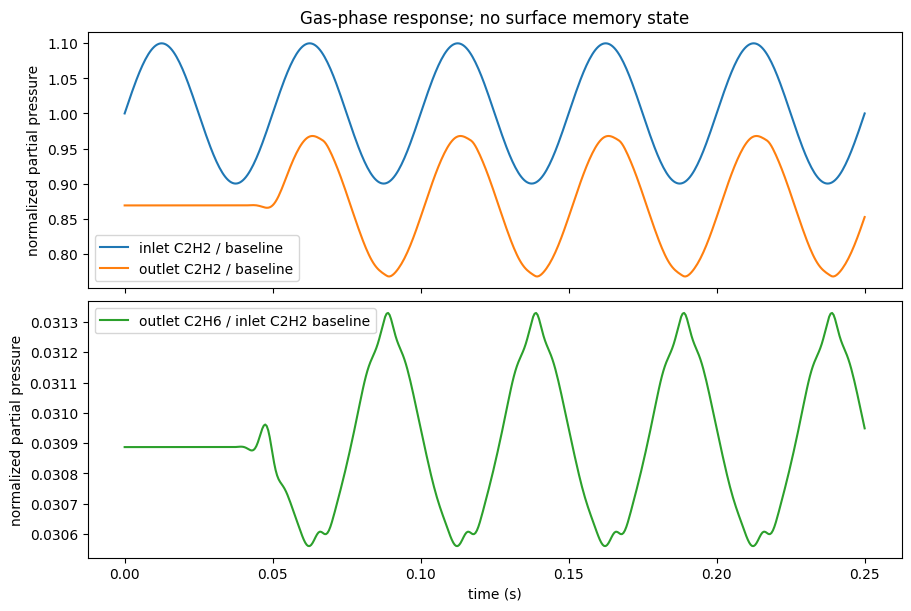

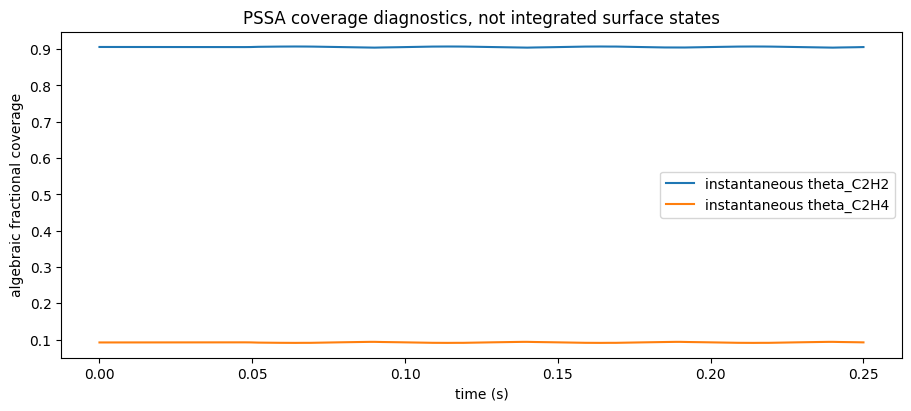

{'success': True, 'message': 'The solver successfully reached the end of the integration interval.', 'nfev': 10023, 'njev': 941, 'nlu': 1829, 'periods': 5, 'minimum_concentration_mol_m3': 0.00010135379560748686}


In [6]:
N_PERIODS, FREQUENCY_HZ, AMPLITUDE = 5, 20.0, 0.10
PERIOD = 1.0 / FREQUENCY_HZ
DURATION = N_PERIODS * PERIOD
sample_t = np.linspace(0.0, DURATION, N_PERIODS * 100 + 1)
base_state_64 = steady_64["state"]
base_inlet_64 = constant_inlet(op64)

def periodic_inlet(t):
    return base_inlet_64 * (1.0 + AMPLITUDE*np.sin(2.0*np.pi*FREQUENCY_HZ*t))

periodic_model_64 = replace(model64, inlet=periodic_inlet)
transient = periodic_model_64.integrate(
    base_state_64, (0.0, DURATION), method="BDF",
    rtol=1e-6, atol=1e-10, max_step=PERIOD/80.0,
    use_sparsity=True, dense_output=True,
)
assert transient.success, transient.message
sample_y = transient.sol(sample_t)
sampled_states = sample_y.T
outlet_gas = np.array([
    periodic_model_64.layout.unpack(y)[0][-1] for y in sampled_states
])
inlet_gas = np.array([periodic_inlet(t) for t in sample_t])
p_in_a = inlet_gas[:, IGAS["C2H2"]] * R_GAS * T_BASE
p_out_a = outlet_gas[:, IGAS["C2H2"]] * R_GAS * T_BASE
p_out_e = outlet_gas[:, IGAS["C2H6"]] * R_GAS * T_BASE
p_scale = Y_FEED["C2H2"] * P_TOTAL
min_transient_concentration = float(sample_y.min())
assert np.isfinite(sample_y).all()
assert min_transient_concentration >= -1e-8

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
axes[0].plot(sample_t, p_in_a/p_scale, label="inlet C2H2 / baseline")
axes[0].plot(sample_t, p_out_a/p_scale, label="outlet C2H2 / baseline")
axes[0].set_ylabel("normalized partial pressure")
axes[0].legend()
axes[0].set_title("Gas-phase response; no surface memory state")
axes[1].plot(sample_t, p_out_e/p_scale, color="tab:green", label="outlet C2H6 / inlet C2H2 baseline")
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("normalized partial pressure")
axes[1].legend()
plt.show()

theta_out = np.array([
    model64.rate.coverages(c * R_GAS*T_BASE, T_BASE) for c in outlet_gas
])
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.plot(sample_t, theta_out[:, 1], label="instantaneous theta_C2H2")
ax.plot(sample_t, theta_out[:, 2], label="instantaneous theta_C2H4")
ax.set_xlabel("time (s)")
ax.set_ylabel("algebraic fractional coverage")
ax.set_title("PSSA coverage diagnostics, not integrated surface states")
ax.legend()
plt.show()

print({
    "success": transient.success, "message": transient.message,
    "nfev": transient.nfev, "njev": transient.njev, "nlu": transient.nlu,
    "periods": N_PERIODS,
    "minimum_concentration_mol_m3": min_transient_concentration,
})


## Resolution and solver sensitivity

Compare the 64-cell baseline with the 128-cell steady solution and repeat the 64-cell periodic solve at tighter BDF tolerances. Targets are below 1% for steady outlet conversion change and below 1% relative RMS change in the outlet acetylene trace. These checks concern only numerical solution of the declared model, not the validity of its assumptions or kinetics.


In [7]:
tight_transient = periodic_model_64.integrate(
    base_state_64, (0.0, DURATION), method="BDF",
    rtol=1e-8, atol=1e-12, max_step=PERIOD/80.0,
    use_sparsity=True, dense_output=True,
)
assert tight_transient.success, tight_transient.message
tight_y = tight_transient.sol(sample_t)
tight_out_a = np.array([
    periodic_model_64.layout.unpack(y)[0][-1, IGAS["C2H2"]]
    for y in tight_y.T
])
base_out_a = outlet_gas[:, IGAS["C2H2"]]
abs_rms = float(np.sqrt(np.mean((base_out_a-tight_out_a)**2)))
rel_rms = abs_rms / max(float(np.sqrt(np.mean((base_out_a-base_out_a.mean())**2))), 1e-15)

print({
    "steady_conversion_change_N64_to_N128": grid_rel_64_128,
    "steady_grid_target": "< 0.01",
    "periodic_outlet_C2H2_relative_RMS_tolerance_change": rel_rms,
    "temporal_target": "< 0.01",
    "baseline_solver_success": transient.success,
    "tight_solver_success": tight_transient.success,
})
assert rel_rms < 0.01


{'steady_conversion_change_N64_to_N128': 6.562432874329782e-06, 'steady_grid_target': '< 0.01', 'periodic_outlet_C2H2_relative_RMS_tolerance_change': 7.660139376973358e-05, 'temporal_target': '< 0.01', 'baseline_solver_success': True, 'tight_solver_success': True}


## Limitations and review boundary

- The PSSA closure and central kinetic values are fitted to steady Urmès data on 0.05 wt% Pd/α-Al₂O₃. They are not PdAg BEP kinetics.
- The source's K₁ conflict remains unresolved: p. 5 text gives 611 Pa⁻¹ and Table 5 p. 6 gives 13 Pa⁻¹. V3 uses 13 for the fitted-model attempt and reports a same-feed sensitivity. No unit-conversion explanation is assumed.
- No dynamic surface coverage, pellet diffusion, film resistance, axial dispersion, energy equation, pressure drop, or variable-total-flow coupling is implemented.
- No-film/no-pellet-gradient criteria apply to the Urmès conditions only. The borrowed bed void fraction and derived bed length make transient residence time uncertain.
- The Table 1 comparison is pooled over two loadings and includes repeatability spread. It is not an exact individual-run reproduction, experimental validation, or BEP result.
- Passing code and numerical checks is separate from reproducing a paper curve and from validating an experiment.

**Owner review remains required before supervisor-facing use.** The personal map has not been edited, and no understanding or citation verification is inferred. See STUDY_PRIORITIES.md and DAMIAN_HANDOFF.md.
